# Credit Risk Model: Probability of Default

This notebook builds and evaluates a probability-of-default (PD) model for consumer loan applications.

1. **Exploratory data analysis** of the eight raw application fields
2. **Feature engineering**: binning, interaction terms and categorical encoding
3. **Statistical tests**: chi-squared, point-biserial / Mann-Whitney, correlation matrix and information value
4. **Modelling**: logistic regression and gradient boosting with scikit-learn
5. **Evaluation**: AUC-ROC, precision-recall, confusion matrix, classification report, calibration

The feature engineering, models and evaluation helpers are imported from `src/`, so the notebook and the
command-line pipeline (`python src/pipeline.py`) run exactly the same code.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import classification_report, roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict

from src.data import load_data
from src.evaluation import (best_f1_threshold, evaluate, metrics_table, plot_calibration,
                            plot_confusion, plot_importance, plot_precision_recall, plot_roc)
from src.features import (CATEGORICAL_FEATURES, NUMERIC_FEATURES, TARGET, FeatureEngineer, add_bins)
from src.pipeline import build_models, split
from src.plotting import BLUE, CLASS_COLORS, CLASS_LABELS, DIVERGING, MODEL_LABELS, ORANGE, set_style
from src.stats import chi_squared_tests, information_value, iv_strength, numeric_significance

set_style()
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
SEED = 42

## 1. Exploratory data analysis

The data is 25,000 **synthetic** loan applications (`data/credit_data.csv`, built by `src/data.py`). Each
applicant has a hidden creditworthiness factor that drives the observed fields, and default is drawn from a
logistic model with some non-linear effects. Part of the risk is deliberately unobservable, so no model can
be perfect.

In [2]:
df = load_data()
print(f"{len(df):,} rows x {df.shape[1]} columns")
df.head()

25,000 rows x 8 columns


,credit_score,annual_income,debt_to_income,num_open_accounts,num_late_payments,loan_amount,loan_purpose,default_flag
0,662,"103,200.0000",0.3060,8,0,"28,050.0000",debt_consolidation,0
1,703,"19,300.0000",0.2330,5,1,"4,750.0000",small_business,0
2,779,"64,200.0000",0.3020,10,0,"10,950.0000",medical,0
3,716,"41,600.0000",0.2240,10,0,"14,400.0000",credit_card,0
4,633,"217,600.0000",0.5290,5,4,"41,800.0000",credit_card,1


In [3]:
summary = df.describe(include="all").T
summary["missing"] = df.isna().sum()
summary["missing_pct"] = df.isna().mean()
summary[["count", "missing", "missing_pct", "mean", "std", "min", "50%", "max", "unique", "top"]]

,count,missing,missing_pct,mean,std,min,50%,max,unique,top
credit_score,"25,000.0000",0,0.0000,690.3651,58.9932,468.0000,691.0000,850.0000,NaN,NaN
annual_income,"24,233.0000",767,0.0307,"75,792.0934","48,325.9045","12,000.0000","63,900.0000","600,000.0000",NaN,NaN
debt_to_income,"25,000.0000",0,0.0000,0.2996,0.1249,0.0000,0.2990,0.7860,NaN,NaN
num_open_accounts,"25,000.0000",0,0.0000,8.9360,5.2997,0.0000,8.0000,79.0000,NaN,NaN
num_late_payments,"25,000.0000",0,0.0000,0.8122,1.2843,0.0000,0.0000,29.0000,NaN,NaN
loan_amount,"25,000.0000",0,0.0000,"16,675.6900","10,555.2249","1,000.0000","13,850.0000","50,000.0000",NaN,NaN
loan_purpose,25000,0,0.0000,NaN,NaN,NaN,NaN,NaN,8,debt_consolidation
default_flag,"25,000.0000",0,0.0000,0.0898,0.2858,0.0000,0.0000,1.0000,NaN,NaN


`annual_income` is missing for about 3% of applicants. It's self-reported, so missingness *can* be
informative. The feature pipeline imputes the training-set median and adds an `income_missing` flag, so the
model can use it if it is. (Section 3 shows it isn't here.)
`num_open_accounts` and `num_late_payments` are right-skewed counts.

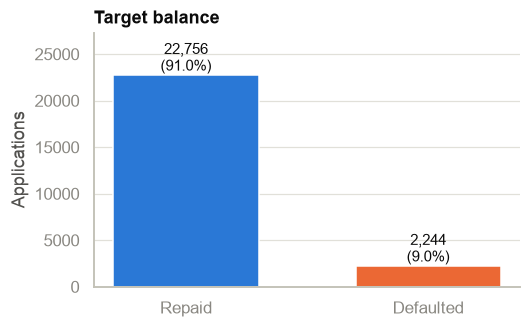

In [4]:
fig, ax = plt.subplots(figsize=(5, 3))
counts = df[TARGET].value_counts().sort_index()
ax.bar([CLASS_LABELS[i] for i in counts.index], counts.values, color=[CLASS_COLORS[i] for i in counts.index], width=0.6)
for i, v in enumerate(counts.values):
    ax.text(i, v, f"{v:,}\n({v / counts.sum():.1%})", ha="center", va="bottom", fontsize=10)
ax.set(title="Target balance", ylabel="Applications", ylim=(0, counts.max() * 1.2))
ax.grid(axis="x", visible=False)
plt.show()

Only about 9% of loans default, so the classes are imbalanced. Accuracy would be misleading here: predicting
"repaid" for everyone scores about 91%. Evaluation therefore relies on AUC, precision-recall and a tuned threshold.

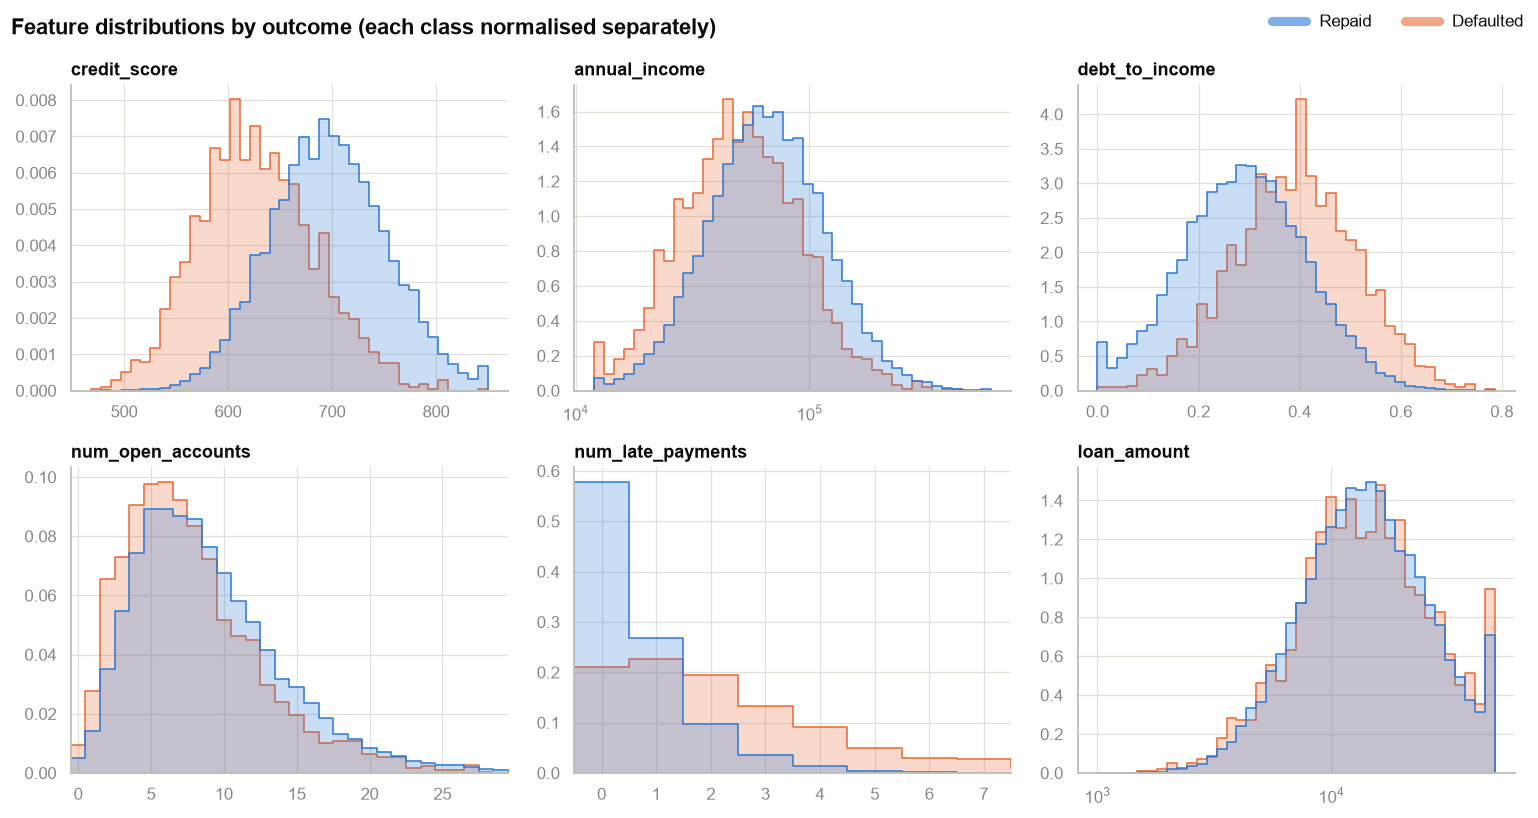

In [5]:
numeric_raw = ["credit_score", "annual_income", "debt_to_income", "num_open_accounts", "num_late_payments", "loan_amount"]
fig, axes = plt.subplots(2, 3, figsize=(14, 7.5))
for ax, col in zip(axes.flat, numeric_raw):
    data = df[[col, TARGET]].dropna()
    log = col in ("annual_income", "loan_amount")
    discrete = col in ("num_open_accounts", "num_late_payments")
    sns.histplot(data, x=col, hue=TARGET, stat="density", common_norm=False, element="step", fill=True,
                 alpha=0.25, palette=CLASS_COLORS, log_scale=log, discrete=discrete, ax=ax, legend=False,
                 **({} if discrete else {"bins": 40}))
    if discrete:
        ax.set_xlim(-0.5, data[col].quantile(0.995) + 0.5)
    ax.set(title=col, xlabel="", ylabel="")
handles = [plt.Line2D([], [], color=CLASS_COLORS[k], lw=6, alpha=0.6) for k in (0, 1)]
fig.legend(handles, [CLASS_LABELS[0], CLASS_LABELS[1]], loc="upper right", ncol=2)
fig.suptitle("Feature distributions by outcome (each class normalised separately)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()

**What stands out**

- **Credit score** separates the classes most clearly. Defaulters' median score is 624 vs 696 for repaid loans.
- **Late payments** and **debt-to-income** shift to the right for defaulters.
- **Income** separates the classes a little. **Loan amount** shows almost no difference on its own. What
  matters is loan size *relative to income*, which gets engineered in section 2.
- **Open accounts** barely differ between the classes, apart from a slightly fatter low tail for
  defaulters (thin credit files).

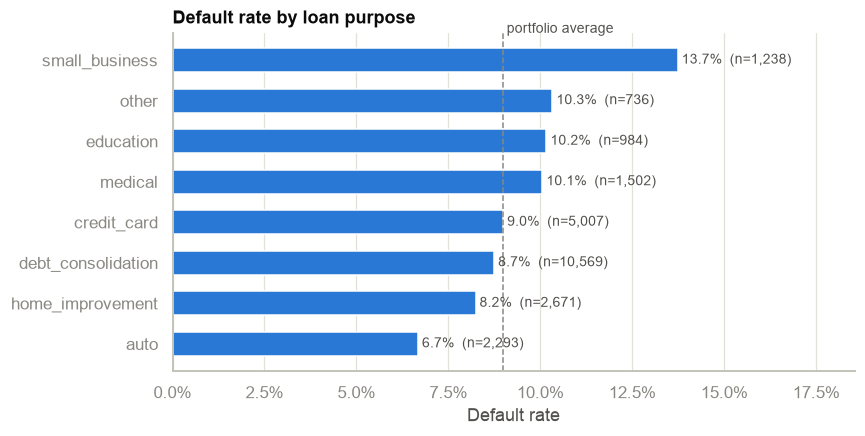

In [6]:
purpose = (df.groupby("loan_purpose")[TARGET].agg(rate="mean", n="size")
             .sort_values("rate"))
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(purpose.index, purpose["rate"], color=BLUE, height=0.6)
ax.axvline(df[TARGET].mean(), color="#898781", ls="--", lw=1)
ax.text(df[TARGET].mean(), len(purpose) - 0.4, " portfolio average", color="#52514e", fontsize=9, va="bottom")
for y, (rate, n) in enumerate(zip(purpose["rate"], purpose["n"])):
    ax.text(rate, y, f" {rate:.1%}  (n={n:,})", va="center", fontsize=9, color="#52514e")
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.set(title="Default rate by loan purpose", xlabel="Default rate", xlim=(0, purpose["rate"].max() * 1.35))
ax.grid(axis="y", visible=False)
plt.show()

## 2. Feature engineering

All of the following lives in `src/features.py` as `FeatureEngineer`, a scikit-learn transformer. It's fitted
inside the model pipeline, so the income median it imputes is learned from training folds only.

| Step | Features |
|---|---|
| **Transforms** | `log_income`, `log_loan_amount` (both are heavily right-skewed) |
| **Missing-value handling** | median-imputed income + `income_missing` flag |
| **Ratio** | `loan_to_income` = loan amount / annual income |
| **Interaction terms** | `dti_x_late` = DTI × late payments; `score_x_dti` = standardised score × DTI |
| **Binning** | FICO-style `credit_score_band`; `dti_band`; `late_payment_band` (0 / 1 / 2-3 / 4+); `open_accounts_band` (thin file 0-2 ... 18+) |
| **Encoding** | one-hot for `loan_purpose` and every band; numeric features standardised |

The bins give the linear model a way to fit non-linear risk: a step in each band rather than one slope.

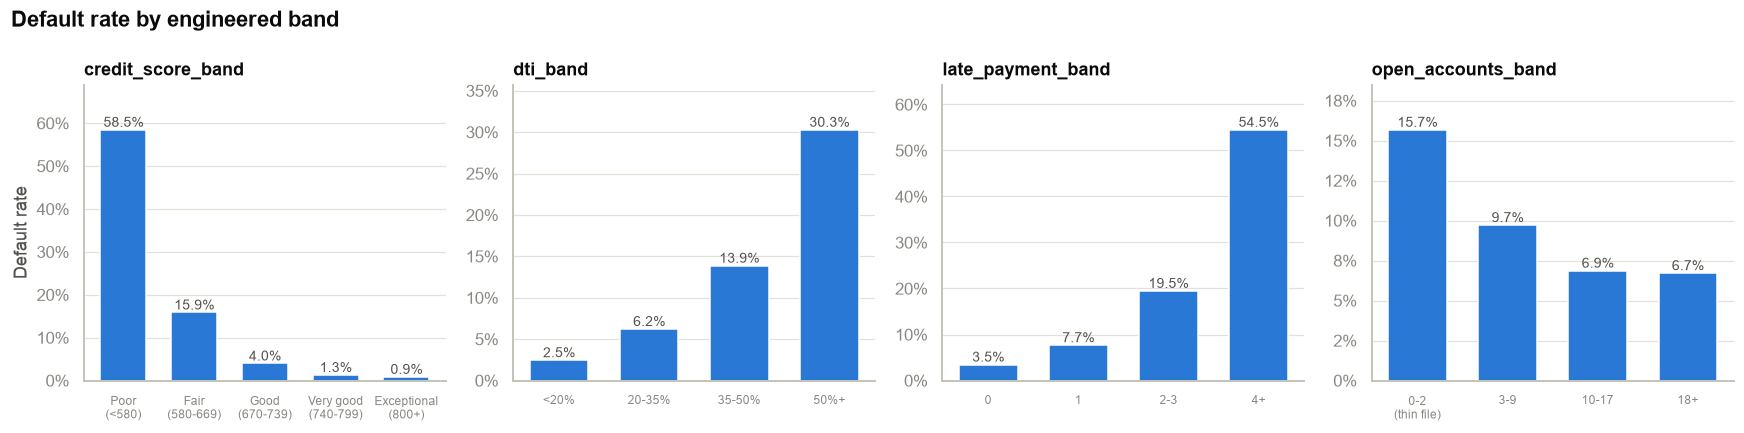

In [7]:
binned = add_bins(df)
bands = ["credit_score_band", "dti_band", "late_payment_band", "open_accounts_band"]
fig, axes = plt.subplots(1, 4, figsize=(16, 4), sharey=False)
for ax, col in zip(axes, bands):
    rates = binned.groupby(col, observed=True)[TARGET].agg(rate="mean", n="size")
    ax.bar(range(len(rates)), rates["rate"], color=BLUE, width=0.65)
    ax.set_xticks(range(len(rates)), [str(c).replace(" (", "\n(") for c in rates.index], fontsize=8)
    for x, r in enumerate(rates["rate"]):
        ax.text(x, r, f"{r:.1%}", ha="center", va="bottom", fontsize=9, color="#52514e")
    ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1, decimals=0))
    ax.set(title=col, ylim=(0, rates["rate"].max() * 1.18))
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("Default rate")
fig.suptitle("Default rate by engineered band", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()

Default rates move **monotonically** across the score, DTI and late-payment bands, so the bins carry a clean
ordinal signal. The open-accounts bands are **not linear**: thin files (0-2 accounts) are riskiest. A single
linear slope would miss that, and the bins capture it.

Next, check whether the DTI × late-payment interaction is real. If the two effects simply added up on the
log-odds scale, there would be nothing for the interaction term to learn.

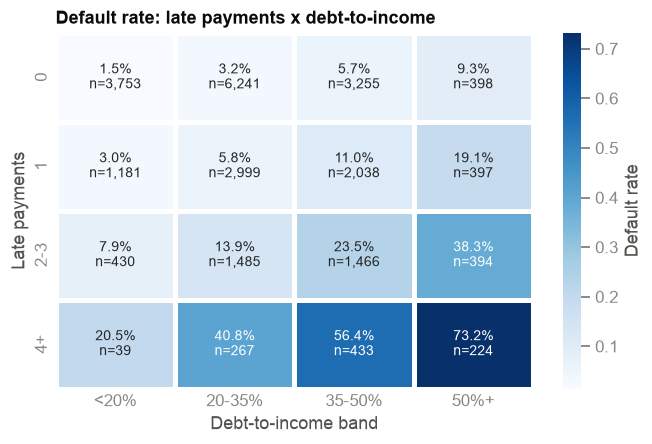

In [8]:
pivot = binned.pivot_table(index="late_payment_band", columns="dti_band", values=TARGET, aggfunc="mean", observed=True)
counts = binned.pivot_table(index="late_payment_band", columns="dti_band", values=TARGET, aggfunc="size", observed=True)
labels = pivot.map(lambda v: f"{v:.1%}") + "\n" + counts.map(lambda n: f"n={n:,}")
fig, ax = plt.subplots(figsize=(7, 4.2))
sns.heatmap(pivot, annot=labels, fmt="", cmap="Blues", cbar_kws={"label": "Default rate"},
            linewidths=2, linecolor="white", ax=ax, annot_kws={"fontsize": 9})
ax.set(title="Default rate: late payments x debt-to-income", xlabel="Debt-to-income band", ylabel="Late payments")
ax.tick_params(length=0)
plt.show()

In absolute terms, late payments hurt far more when DTI is high. Moving from the lowest to the highest DTI
band adds about 8 percentage points of default risk for borrowers with no late payments, but more than 50 points
for those with 4+. On the log-odds scale the two effects are closer to additive, so the interaction is real but
modest. `dti_x_late` gives the linear model a direct way to express it.

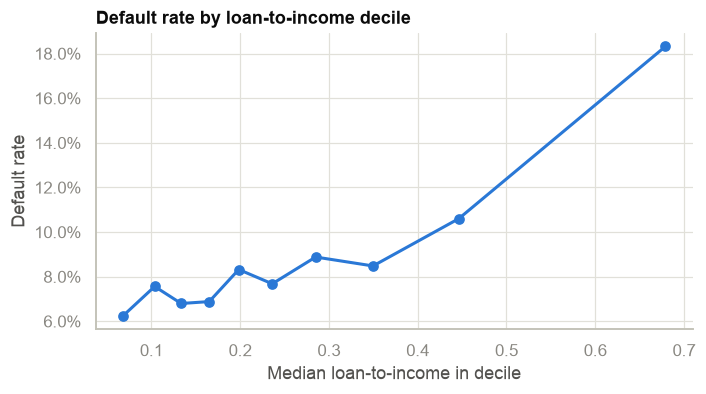

In [9]:
lti = FeatureEngineer().fit(df).transform(df)[["loan_to_income"]].assign(default=df[TARGET].values)
lti["decile"] = pd.qcut(lti["loan_to_income"], 10)
by_decile = lti.groupby("decile", observed=True).agg(lti=("loan_to_income", "median"), rate=("default", "mean"))
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(by_decile["lti"], by_decile["rate"], marker="o", color=BLUE)
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.set(title="Default rate by loan-to-income decile", xlabel="Median loan-to-income in decile", ylabel="Default rate")
plt.show()

The default rate stays in a 6-9% range until loan-to-income reaches about 0.35, then rises sharply. The top
decile defaults at about 18%. That's a threshold effect: gradient boosting can learn the kink directly, and
the logistic model approximates it with the linear term.

The engineered frame that goes into the encoder:

In [10]:
fe = FeatureEngineer().fit(df)
engineered = fe.transform(df)
display(engineered.head())

from src.features import build_preprocessor
encoder = build_preprocessor().fit(engineered)
encoded_names = encoder.get_feature_names_out()
print(f"{len(NUMERIC_FEATURES)} numeric + {len(CATEGORICAL_FEATURES)} categorical features "
      f"-> {len(encoded_names)} model inputs after one-hot encoding")

,credit_score,log_income,debt_to_income,num_open_accounts,num_late_payments,log_loan_amount,loan_to_income,dti_x_late,score_x_dti,income_missing,loan_purpose,credit_score_band,dti_band,late_payment_band,open_accounts_band
0,662,11.5444,0.3060,8,0,10.2417,0.2718,0.0000,-0.1428,0,debt_consolidation,Fair (580-669),20-35%,0,3-9
1,703,9.8679,0.2330,5,1,8.4659,0.2461,0.2330,0.0505,0,small_business,Good (670-739),20-35%,1,3-9
2,779,11.0698,0.3020,10,0,9.3011,0.1706,0.0000,0.4480,0,medical,Very good (740-799),20-35%,0,10-17
3,716,10.6359,0.2240,10,0,9.5750,0.3462,0.0000,0.0971,0,credit_card,Good (670-739),20-35%,0,10-17
4,633,12.2904,0.5290,5,4,10.6407,0.1921,2.1160,-0.5026,0,credit_card,Fair (580-669),50%+,4+,3-9


10 numeric + 5 categorical features -> 35 model inputs after one-hot encoding


## 3. Statistical tests of feature significance

With 25,000 rows, almost any difference is statistically significant. The p-values filter out noise, but
**effect sizes** (Cramer's V, correlation, information value) are what rank the features.

### 3a. Chi-squared tests of independence (categorical and binned features)

In [11]:
analysis = engineered.assign(**{TARGET: df[TARGET].values})
chi = chi_squared_tests(analysis, CATEGORICAL_FEATURES, TARGET)
chi["significant (p < 0.05)"] = chi["p_value"] < 0.05
chi.style.format({"chi2": "{:,.1f}", "p_value": "{:.2e}", "cramers_v": "{:.3f}"}).hide(axis="index")

feature,chi2,dof,p_value,cramers_v,significant (p < 0.05)
late_payment_band,"3,475.0",3,0.00e+00,0.373,True
credit_score_band,"3,397.2",4,0.00e+00,0.369,True
dti_band,"1,379.0",3,1.05e-298,0.235,True
open_accounts_band,143.0,3,8.41e-31,0.076,True
loan_purpose,57.1,7,5.64e-10,0.048,True


Every categorical feature rejects independence from default at p < 0.05. The late-payment, score and DTI bands
show moderate associations (Cramer's V of 0.37, 0.37 and 0.23). `open_accounts_band` (0.08) and `loan_purpose`
(0.05) are significant but weak: real, small effects.

### 3b. Numeric features: point-biserial correlation and Mann-Whitney U

In [12]:
num = numeric_significance(analysis, NUMERIC_FEATURES, TARGET)
num.style.format({"point_biserial_r": "{:+.3f}", "p_value_r": "{:.2e}", "mann_whitney_p": "{:.2e}",
                  "median_default": "{:,.3f}", "median_repaid": "{:,.3f}"}).hide(axis="index")

feature,point_biserial_r,p_value_r,mann_whitney_p,median_default,median_repaid
dti_x_late,+0.411,0.00e+00,0.00e+00,0.643,0.000
score_x_dti,-0.384,0.00e+00,0.00e+00,-0.404,0.017
num_late_payments,+0.383,0.00e+00,0.00e+00,2.000,0.000
credit_score,-0.334,0.00e+00,0.00e+00,624.000,696.000
debt_to_income,+0.230,1.70e-296,9.83e-261,0.394,0.291
loan_to_income,+0.148,3.06e-122,2.33e-46,0.267,0.213
log_income,-0.129,7.43e-93,9.27e-86,10.848,11.065
num_open_accounts,-0.066,1.74e-25,1.42e-30,7.000,8.000
income_missing,-0.007,2.56e-01,2.56e-01,0.000,0.000
log_loan_amount,+0.000,9.49e-01,8.86e-01,9.536,9.536


The point-biserial correlation measures linear association with default. The Mann-Whitney U test is a
non-parametric check that the two groups' distributions differ, which suits skewed counts.

- The two **interaction terms** have the strongest linear correlations of all (|r| about 0.38-0.41), above any
  of their parent features.
- `num_open_accounts` has a tiny linear correlation (r ≈ -0.07), yet the band analysis showed a real non-linear
  thin-file effect. That gap is why it's binned.
- `income_missing` and `log_loan_amount` are **not** significant on their own (the Mann-Whitney test can't reject
  equal distributions). Loan amount matters only through `loan_to_income`.

### 3c. Correlation matrix

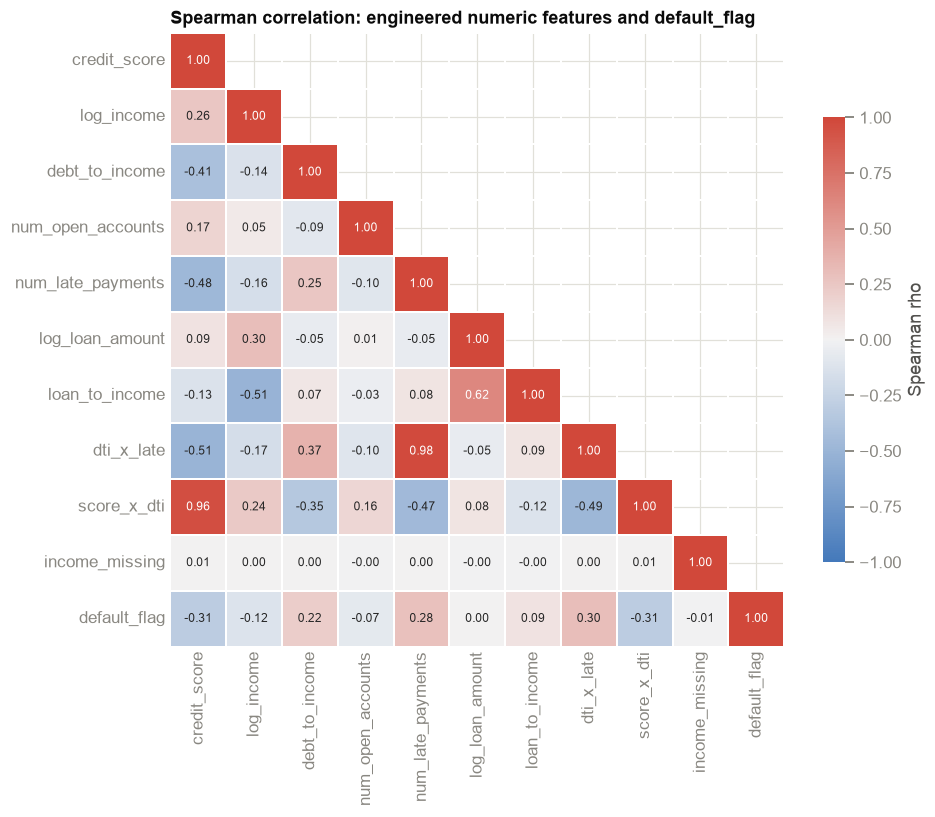

In [13]:
corr = analysis[NUMERIC_FEATURES + [TARGET]].corr(method="spearman")
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
fig, ax = plt.subplots(figsize=(9, 7.5))
sns.heatmap(corr, mask=mask, cmap=DIVERGING, vmin=-1, vmax=1, center=0, annot=True, fmt=".2f",
            annot_kws={"fontsize": 8}, linewidths=1, linecolor="white", square=True,
            cbar_kws={"shrink": 0.7, "label": "Spearman rho"}, ax=ax)
ax.set(title="Spearman correlation: engineered numeric features and default_flag")
ax.tick_params(length=0)
plt.show()

- The bottom row is each feature's rank correlation with default. Credit score and `score_x_dti` (negative),
  then `dti_x_late`, late payments and DTI lead.
- **Two interaction terms nearly duplicate a parent in rank order.** `dti_x_late` vs `num_late_payments` has
  ρ = 0.98, because the product is zero whenever late payments are zero. `score_x_dti` vs `credit_score` has
  ρ = 0.96. They still add information in *magnitude*: both have a larger point-biserial correlation with
  default than their parents (3b).
- `log_loan_amount` and `loan_to_income` (0.62) and `log_income` and `loan_to_income` (-0.51) are moderately
  correlated by construction.
- The logistic regression is **L2-regularised** (`C=0.5`) so coefficients stay stable under this collinearity;
  trees are unaffected. A production scorecard would usually keep one feature from each near-duplicate pair, or
  mean-centre the parents before forming the product, to keep coefficients interpretable.

### 3d. Information value (weight of evidence)

Information value (IV) is the credit-scoring industry's standard univariate screen. Numeric features are cut
into deciles first.

In [14]:
iv_input = analysis.copy()
for col in ["credit_score", "debt_to_income", "num_late_payments", "log_income", "loan_to_income",
            "dti_x_late", "num_open_accounts", "log_loan_amount"]:
    iv_input[col] = pd.qcut(iv_input[col], 10, duplicates="drop")
iv_rows = []
for col in ["credit_score", "num_late_payments", "debt_to_income", "dti_x_late", "loan_to_income", "log_income",
            "log_loan_amount", "num_open_accounts", "loan_purpose"]:
    iv, _ = information_value(iv_input, col, TARGET)
    iv_rows.append({"feature": col, "information_value": iv, "strength": iv_strength(iv)})
iv_table = pd.DataFrame(iv_rows).sort_values("information_value", ascending=False)
iv_table.style.format({"information_value": "{:.3f}"}).hide(axis="index")

feature,information_value,strength
credit_score,1.405,strong
dti_x_late,1.156,strong
num_late_payments,0.928,strong
debt_to_income,0.645,strong
log_income,0.201,medium
loan_to_income,0.133,medium
num_open_accounts,0.067,weak
loan_purpose,0.026,weak
log_loan_amount,0.006,useless


Taken together, the tests agree:

- **Strong** (IV > 0.3): credit score, late payments, the DTI × late interaction, and DTI.
- **Medium**: income and loan-to-income.
- **Weak but significant**: open accounts and loan purpose. They stay in because their effects are small but
  real and non-linear.
- **Useless on its own**: `log_loan_amount` (IV 0.006), and the `income_missing` flag is not significant. Both
  are kept because they cost little: L2 regularisation shrinks them, and loan amount is needed to form
  loan-to-income. A production scorecard would likely drop them for parsimony.

## 4. Modelling

- **Split**: stratified 80/20 train/test. The test set is touched exactly once, in section 5.
- **Logistic regression**: L2 penalty, `C=0.5`, on the full engineered and encoded feature set.
- **Gradient boosting**: `GradientBoostingClassifier` with 300 trees, learning rate 0.05, depth 3,
  subsample 0.8 and min 50 samples per leaf. These are deliberately conservative settings for a noisy,
  imbalanced target.
- **Cross-validation**: 5-fold stratified CV on the training set, both to estimate AUC and to produce
  out-of-fold predictions. The decision threshold is chosen from those, never from the test set.

In [15]:
X_train, X_test, y_train, y_test = split(df, test_size=0.2, seed=SEED)
print(f"train: {len(X_train):,} rows ({y_train.mean():.2%} default)   test: {len(X_test):,} rows ({y_test.mean():.2%} default)")

models = build_models(SEED)
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
oof, cv_summary = {}, []
for name, model in models.items():
    oof[name] = cross_val_predict(model, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
    fold_auc = [roc_auc_score(y_train.iloc[v], oof[name][v]) for _, v in cv.split(X_train, y_train)]
    cv_summary.append({"model": MODEL_LABELS[name], "cv_auc_mean": np.mean(fold_auc), "cv_auc_std": np.std(fold_auc),
                       "folds": ", ".join(f"{a:.3f}" for a in fold_auc)})
pd.DataFrame(cv_summary)

train: 20,000 rows (8.97% default)   test: 5,000 rows (8.98% default)


,model,cv_auc_mean,cv_auc_std,folds
0,Logistic regression,0.8414,0.0097,"0.858, 0.841, 0.845, 0.830, 0.833"
1,Gradient boosting,0.8398,0.0097,"0.856, 0.841, 0.839, 0.826, 0.837"


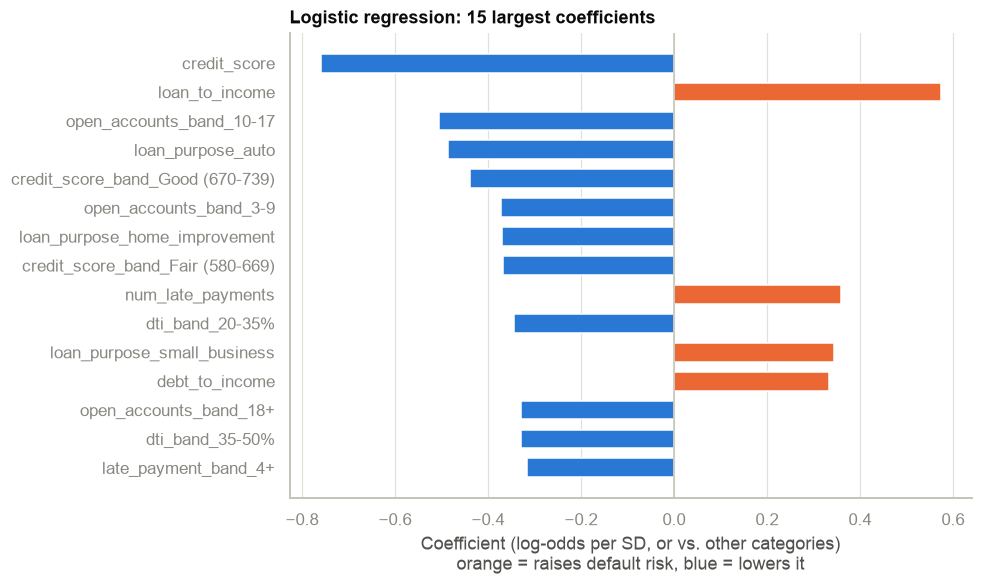

In [16]:
for model in models.values():
    model.fit(X_train, y_train)

lr = models["logistic_regression"]
coefs = pd.Series(lr.named_steps["model"].coef_[0], index=lr.named_steps["encode"].get_feature_names_out())
top = coefs.reindex(coefs.abs().sort_values(ascending=False).index).head(15)[::-1]
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(top.index, top.values, color=[ORANGE if v > 0 else BLUE for v in top.values], height=0.65)
ax.axvline(0, color="#c3c2b7", lw=1)
ax.set(title="Logistic regression: 15 largest coefficients",
       xlabel="Coefficient (log-odds per SD, or vs. other categories)\norange = raises default risk, blue = lowers it")
ax.grid(axis="y", visible=False)
plt.show()

The coefficients line up with the EDA and the tests. Credit score lowers risk, while loan-to-income, late
payments and DTI raise it. The bands add non-linear corrections on top of the linear terms. One-hot bands are
relative to each other, and the *Poor (<580)* coefficient sits about 0.3 above the Fair and Good bands: extra
risk beyond what the linear score term implies. Thin files (0-2 accounts) carry risk relative to every other
account band.

`log_income` has a *positive* coefficient even though income lowers risk on its own. Its effect is already
carried by `loan_to_income`; given that ratio, the remaining income term is picking up collinearity. This is a
standard reason to read coefficients jointly, not one at a time.

## 5. Evaluation on the held-out test set

The decision threshold for each model is the cut-off that maximises F1 on its **out-of-fold training
predictions**. With a 9% base rate, the default 0.5 threshold would flag very few loans.

In [17]:
scores, results = {}, {}
for name, model in models.items():
    proba = model.predict_proba(X_test)[:, 1]
    threshold = best_f1_threshold(y_train, oof[name])
    scores[name] = (y_test.to_numpy(), proba)
    results[name] = evaluate(y_test, proba, threshold)

metrics_table(results).round(4)

,roc_auc,gini,ks,average_precision,brier_score,threshold,precision,recall,f1
Logistic regression,0.8481,0.6962,0.5352,0.4807,0.0619,0.2056,0.4224,0.5212,0.4666
Gradient boosting,0.8417,0.6835,0.5129,0.4628,0.0629,0.2191,0.4390,0.4967,0.4660


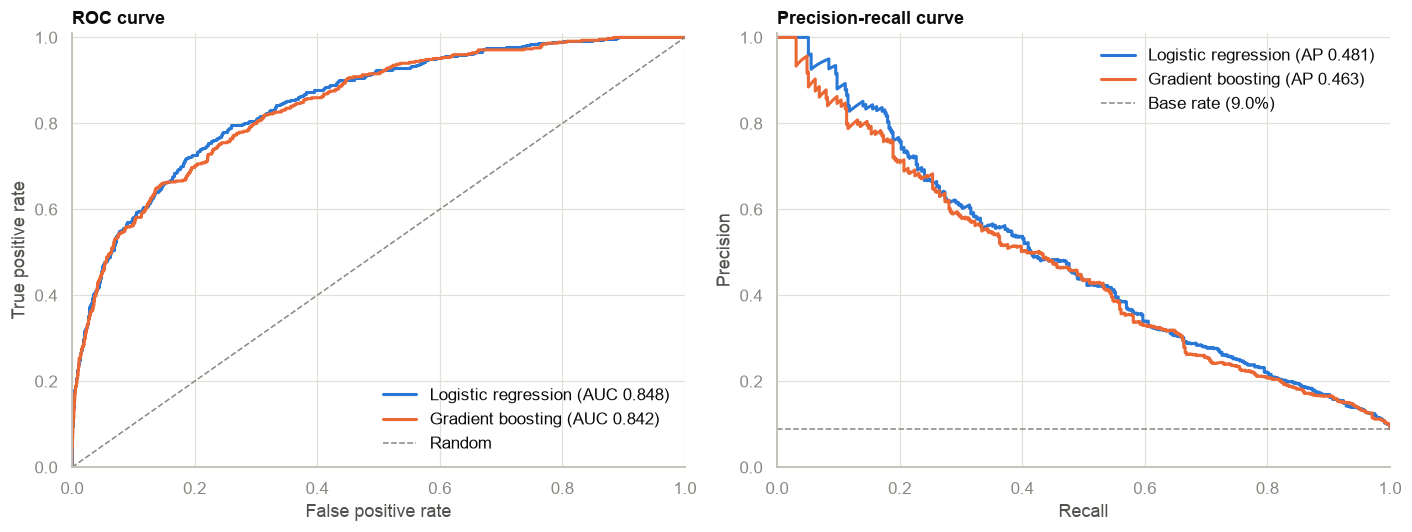

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
plot_roc(scores, axes[0])
plot_precision_recall(scores, axes[1])
fig.tight_layout()
plt.show()

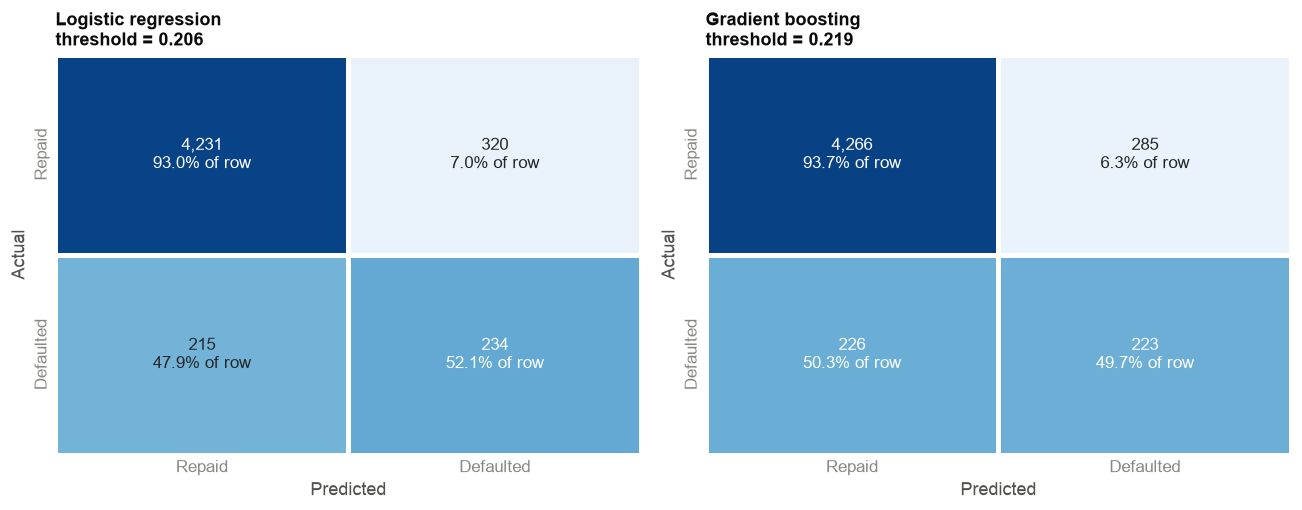

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, (name, (y, p)) in zip(axes, scores.items()):
    plot_confusion(y, p, results[name]["threshold"], MODEL_LABELS[name], ax)
fig.tight_layout()
plt.show()

In [20]:
for name, (y, p) in scores.items():
    t = results[name]["threshold"]
    print(f"{MODEL_LABELS[name]}  (threshold {t:.3f})")
    print(classification_report(y, (p >= t).astype(int), target_names=["Repaid", "Defaulted"], digits=3))

Logistic regression  (threshold 0.206)
              precision    recall  f1-score   support

      Repaid      0.952     0.930     0.941      4551
   Defaulted      0.422     0.521     0.467       449

    accuracy                          0.893      5000
   macro avg      0.687     0.725     0.704      5000
weighted avg      0.904     0.893     0.898      5000

Gradient boosting  (threshold 0.219)
              precision    recall  f1-score   support

      Repaid      0.950     0.937     0.943      4551
   Defaulted      0.439     0.497     0.466       449

    accuracy                          0.898      5000
   macro avg      0.694     0.717     0.705      5000
weighted avg      0.904     0.898     0.901      5000



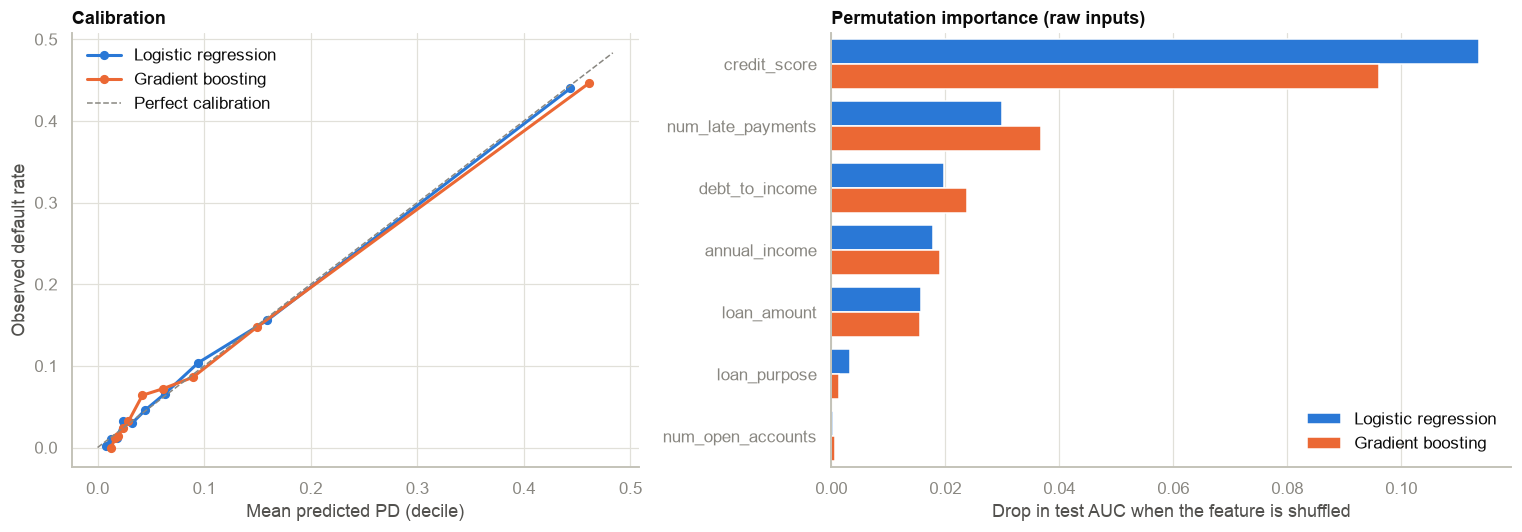

In [21]:
from sklearn.inspection import permutation_importance

importance = pd.DataFrame({
    name: pd.Series(permutation_importance(m, X_test, y_test, scoring="roc_auc", n_repeats=5,
                                           random_state=SEED).importances_mean, index=X_test.columns)
    for name, m in models.items()
}).sort_values("logistic_regression", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1, 1.2]})
plot_calibration(scores, axes[0])
plot_importance(importance, axes[1])
fig.tight_layout()
plt.show()

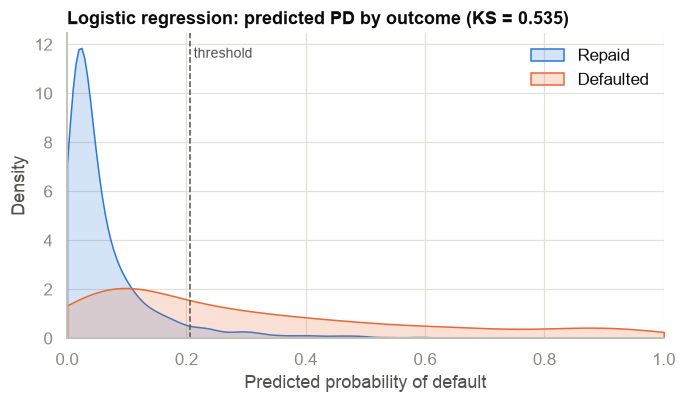

In [22]:
y, p = scores["logistic_regression"]
fig, ax = plt.subplots(figsize=(7, 3.6))
for cls in (0, 1):
    sns.kdeplot(p[y == cls], ax=ax, color=CLASS_COLORS[cls], fill=True, alpha=0.2, label=CLASS_LABELS[cls],
                clip=(0, 1), common_norm=False)
ax.axvline(results["logistic_regression"]["threshold"], color="#52514e", ls="--", lw=1)
ax.text(results["logistic_regression"]["threshold"], ax.get_ylim()[1] * 0.92, " threshold", color="#52514e", fontsize=9)
ax.set(title=f"Logistic regression: predicted PD by outcome (KS = {results['logistic_regression']['ks']:.3f})",
       xlabel="Predicted probability of default", ylabel="Density", xlim=(0, 1))
ax.legend()
plt.show()

## 6. Conclusions

| Metric (test set, n = 5,000) | Logistic regression | Gradient boosting |
|---|---|---|
| 5-fold CV AUC (train) | 0.841 ± 0.010 | 0.840 ± 0.010 |
| **Test AUC-ROC** | **0.848** | 0.842 |
| Gini | 0.696 | 0.684 |
| KS | 0.535 | 0.513 |
| Average precision (PR-AUC) | 0.481 | 0.463 |
| Brier score | 0.0619 | 0.0629 |
| Recall / precision on defaults at the F1 threshold | 52.1% / 42.2% | 49.7% / 43.9% |

1. **The two models perform about the same.** The AUC gap (0.006) is smaller than the fold-to-fold CV spread
   (±0.010). The binned features and interaction terms give logistic regression the non-linearity that gradient
   boosting would otherwise have to find for itself.
2. **Logistic regression is the recommended model.** For equal accuracy it is transparent: each coefficient can
   be audited, turned into scorecard points, and used to generate adverse-action reasons. Those matter for
   credit decisions under fair-lending rules.
3. **Both models are well calibrated.** Predicted PDs track observed default rates across deciles, so the
   scores can be used directly as probabilities for pricing or expected-loss estimates.
4. **Operating point.** At the F1-maximising threshold (≈ 0.21, chosen on training folds), logistic regression
   flags 554 of 5,000 applications (11%). It catches 52% of the defaulters, and 42% of the flagged applications
   do default, versus 9% at random. The F1 threshold is only a neutral default; a real cut-off should come from
   the business cost of a missed default vs a declined good customer.
5. **Risk drivers.** Credit score dominates, followed by late payments, DTI, income and loan size relative to
   income. Loan purpose and open accounts contribute little.

**Limitations and next steps.** The data is synthetic, and about half of each applicant's risk is deliberately
unobservable, which caps achievable AUC. Next steps on real data would be:

- out-of-time validation (train on older vintages, test on newer ones);
- a hyperparameter search;
- monotonic constraints on the boosting model (`HistGradientBoostingClassifier(monotonic_cst=...)`);
- reject inference, since a lender only observes outcomes for approved loans.